# ANALISIS SENTIMEN PROGRAM MAKAN BERGIZI GRATIS (MBG) MENGGUNAKAN MULTINOMIAL NAIVE BAYES (MNB)

Notebook ini berisi implementasi model Klasifikasi Sentimen berbasis **Multinomial Naive Bayes (MNB)** sebagai model pembanding (baseline) terhadap pendekatan Deep Learning (FastText + BiLSTM) pada proyek mata kuliah Machine Learning dengan judul:

**"Sistem Pengambilan Keputusan Hasil Analisis Sentimen terhadap Program Presiden Makan Bergizi Gratis (MBG)"**

### Tahapan Eksperimen:
1. **Import Library & Konfigurasi**: Membaca library visualisasi dan pemrosesan teks.
2. **Memuat Dataset**: Mengakses dua dataset dari Google Drive (`MBG_sentiment_analysis.csv` & `komentar-mbg.csv`).
3. **Preprocessing & Penggabungan**: Case folding, regex cleaning, penggabungan, dan pembersihan menyeluruh.
4. **Pelabelan Leksikon**: Pelabelan otomatis berbasis kamus opini Indonesia dengan aturan negasi.
5. **Pembagian Dataset**: Splitting 80:10:10 (Train, Validation, Test) secara stratifikasi.
6. **Ekstraksi Fitur TF-IDF**: Vectorization text menggunakan `TfidfVectorizer(max_features=5000)` bebas dari kebocoran data (*data leakage*).
7. **Tuning & Pelatihan Model**: Eksperimen hyperparameter smoothing `alpha` pada Validation Set.
8. **Evaluasi & Visualisasi**: Evaluasi performa model terbaik di Test Set menggunakan Confusion Matrix dan Metrik Barplot.
9. **Prediksi Teks Baru**: Implementasi praktis prediksi teks beserta estimasi probabilitas.
10. **Penyimpanan Model**: Menyimpan model MNB dan TF-IDF Vectorizer ke Google Drive.

In [79]:
# ==========================================
# BAGIAN 2: IMPORT LIBRARY DAN KONFIGURASI
# ==========================================

import os
import re
import pickle
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Konfigurasi Grafik
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 6)
plt.rcParams['font.size'] = 11

# Konfigurasi Global
RANDOM_STATE = 42
MAX_FEATURES = 5000
LABEL_NAMES = ['Negatif', 'Netral', 'Positif']

print("Library berhasil diimpor dan konfigurasi global telah ditetapkan.")

Library berhasil diimpor dan konfigurasi global telah ditetapkan.


In [80]:
# ==========================================
# BAGIAN 3: MEMUAT DAN MEMERIKSA DATASET
# ==========================================

from google.colab import drive
print("Silakan lakukan mount Google Drive Anda...")
drive.mount('/content/drive')

# Path Direktori Dataset
dataset_dir = "/content"
file_1_path = os.path.join(dataset_dir, 'MBG_sentiment_analysis.csv')
file_2_path = os.path.join(dataset_dir, 'komentar-mbg.csv')

# Pemeriksaan & Pembacaan Dataset
try:
    df1 = pd.read_csv(file_1_path)
    print(f"\nDataset 1 berhasil dimuat: {file_1_path}")
    print(f"Dimensi Dataset 1: {df1.shape}")
    display(df1.head())
except Exception as e:
    print(f"Gagal memuat Dataset 1! Pastikan file berada di Drive. Error: {e}")

try:
    df2 = pd.read_csv(file_2_path)
    print(f"\nDataset 2 berhasil dimuat: {file_2_path}")
    print(f"Dimensi Dataset 2: {df2.shape}")
    display(df2.head())
except Exception as e:
    print(f"Gagal memuat Dataset 2! Pastikan file berada di Drive. Error: {e}")

Silakan lakukan mount Google Drive Anda...
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Dataset 1 berhasil dimuat: /content/MBG_sentiment_analysis.csv
Dimensi Dataset 1: (11375, 6)


,comment,cleaning,case_folding,normalisasi,tokenize,stopword removal
0,Justru sekarang tio harus WASPADA terhadap par...,Justru sekarang tio harus WASPADA terhadap par...,justru sekarang tio harus waspada terhadap par...,justru sekarang tio harus waspada terhadap par...,"['justru', 'sekarang', 'tio', 'harus', 'waspad...",tio waspada pembenci prabowo memanfaatkan situasi
1,"Org yg ingin sj,, apalagi merencanakan, trlebi...",Org yg ingin sj apalagi merencanakan trlebih l...,org yg ingin sj apalagi merencanakan trlebih l...,orang yang ingin saja apalagi merencanakan trl...,"['orang', 'yang', 'ingin', 'saja', 'apalagi', ...",merencanakan trlebih melaksanakan merugikan hi...
2,Tiyo ardianto kamu anak keturunan anjing kurap...,Tiyo ardianto kamu anak keturunan anjing kurap...,tiyo ardianto kamu anak keturunan anjing kurap...,tiyo ardianto kamu anak keturunan anjing kurap...,"['tiyo', 'ardianto', 'kamu', 'anak', 'keturuna...",tiyo ardianto anak keturunan anjing kurapprofo...
3,Lanjutkan abanku perjuangan mu jgn takut untuk...,Lanjutkan abanku perjuangan mu jgn takut untuk...,lanjutkan abanku perjuangan mu jgn takut untuk...,lanjutkan abanku perjuangan mu jangan takut un...,"['lanjutkan', 'abanku', 'perjuangan', 'mu', 'j...",lanjutkan abanku perjuangan takut teror prjuan...
4,KETUM PARTAI MENGHILANG : karena Kritik TIYO J...,KETUM PARTAI MENGHILANG karena Kritik TIYO JU...,ketum partai menghilang karena kritik tiyo ju...,ketum partai menghilang karena kritik tiyo juj...,"['ketum', 'partai', 'menghilang', 'karena', 'k...",ketum partai menghilang kritik tiyo jujur blok...



Dataset 2 berhasil dimuat: /content/komentar-mbg.csv
Dimensi Dataset 2: (15000, 4)


,author,comment,likes,published_at
0,@djai262,Justru sekarang tio harus WASPADA terhadap par...,0,2026-06-24T06:13:13Z
1,@jumahirsag8710,"Org yg ingin sj,, apalagi merencanakan, trlebi...",0,2026-06-24T05:38:52Z
2,@AndriBoss-i4k,Tiyo ardianto kamu anak keturunan anjing kurap...,0,2026-06-24T04:17:53Z
3,@JohanJoyboy,Lanjutkan abanku perjuangan mu jgn takut untuk...,0,2026-06-24T03:29:09Z
4,@SriSamin,KETUM PARTAI MENGHILANG : karena Kritik TIYO J...,0,2026-06-24T00:48:07Z


In [81]:
# ==========================================
# BAGIAN 4: PREPROCESSING DAN PENGGABUNGAN DATASET
# ==========================================

import pandas as pd
import re

def clean_text_dataset_2(text):
    if not isinstance(text, str):
        return ""
    # Case folding
    text = text.lower()
    # Hapus URL
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    # Hapus mention dan hashtag
    text = re.sub(r'@[\w:]+||#[\w:]+', '', text)
    # Hapus angka, simbol, dan tanda baca
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    # Hapus spasi berlebih
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# Memeriksa apakah variabel df1 dan df2 sudah didefinisikan di runtime colab
if 'df1' not in globals() or 'df2' not in globals():
    print("[PERINGATAN] Variabel 'df1' atau 'df2' belum didefinisikan!")
    print("Harap pastikan Anda telah mengunggah dataset ke Google Drive Anda pada path berikut:")
    print(" - /content/drive/MyDrive/sentimen mbg dataset/MBG_sentiment_analysis.csv")
    print(" - /content/drive/MyDrive/sentimen mbg dataset/komentar-mbg.csv")
    print("Dan pastikan sel BAGIAN 3 telah dieksekusi dengan sukses tanpa ada pesan error.")
else:
    # 1. Proses Dataset Pertama (Gunakan kolom 'stopword removal')
    print("Memproses Dataset Pertama...")
    df1_clean = df1[['stopword removal']].copy()
    df1_clean = df1_clean.rename(columns={'stopword removal': 'text_bersih'})
    df1_clean['sumber'] = 'dataset_1'
    df1_clean = df1_clean.dropna(subset=['text_bersih'])
    df1_clean = df1_clean[df1_clean['text_bersih'].str.strip() != ""]
    print(f"Dataset 1 setelah dibersihkan: {len(df1_clean)} baris.")

    # 2. Proses Dataset Kedua (Gunakan kolom 'comment')
    print("\nMemproses Dataset Kedua...")
    df2_clean = pd.DataFrame()
    if 'comment' in df2.columns:
        df2_clean['text_bersih'] = df2['comment'].apply(clean_text_dataset_2)
        df2_clean['sumber'] = 'dataset_2'
        df2_clean = df2_clean.dropna(subset=['text_bersih'])
        df2_clean = df2_clean[df2_clean['text_bersih'].str.strip() != ""]
        print(f"Dataset 2 setelah dibersihkan: {len(df2_clean)} baris.")
    else:
        print("Kolom 'comment' tidak ditemukan pada Dataset 2!")

    # 3. Penggabungan Kedua Dataset
    df_gabungan = pd.concat([df1_clean, df2_clean], ignore_index=True)
    print(f"\nJumlah total data setelah penggabungan: {len(df_gabungan)} baris.")

    # Final cleaning untuk memastikan tidak ada string kosong atau NaN
    df_gabungan['text_bersih'] = df_gabungan['text_bersih'].astype(str).str.strip()
    df_gabungan = df_gabungan[df_gabungan['text_bersih'] != ""]
    df_gabungan = df_gabungan.drop_duplicates(subset=['text_bersih']).reset_index(drop=True)
    print(f"Jumlah total data setelah penghapusan duplikasi/teks kosong: {len(df_gabungan)} baris.")

Memproses Dataset Pertama...
Dataset 1 setelah dibersihkan: 11259 baris.

Memproses Dataset Kedua...
Dataset 2 setelah dibersihkan: 14865 baris.

Jumlah total data setelah penggabungan: 26124 baris.
Jumlah total data setelah penghapusan duplikasi/teks kosong: 21507 baris.


Berhasil memuat 1182 kata positif dan 2402 kata negatif.

Distribusi Label Sentimen Leksikon:
Negatif (Kelas 0): 6698 data (31.14%)
Netral (Kelas 1): 7335 data (34.11%)
Positif (Kelas 2): 7474 data (34.75%)


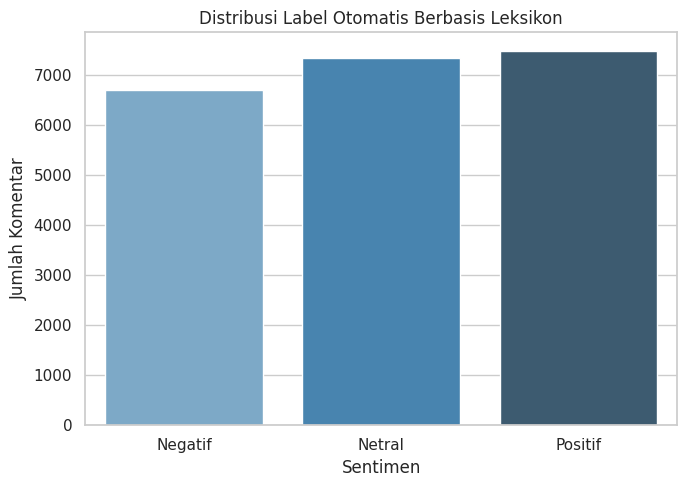

In [82]:
# ==========================================
# BAGIAN 5: PELABELAN SENTIMEN BERBASIS LEKSIKON
# ==========================================

# Download kamus opini Indonesia
url_pos = "https://raw.githubusercontent.com/masdevid/ID-OpinionWords/master/positive.txt"
url_neg = "https://raw.githubusercontent.com/masdevid/ID-OpinionWords/master/negative.txt"

try:
    res_pos = requests.get(url_pos, timeout=10)
    res_neg = requests.get(url_neg, timeout=10)
    res_pos.raise_for_status()
    res_neg.raise_for_status()

    positive_words = set(res_pos.text.splitlines())
    negative_words = set(res_neg.text.splitlines())
    print(f"Berhasil memuat {len(positive_words)} kata positif dan {len(negative_words)} kata negatif.")
except Exception as e:
    print(f"Gagal memuat kamus opini: {e}. Menggunakan fallback manual.")
    positive_words = {"bagus", "setuju", "baik", "dukung", "bermanfaat", "sehat", "makan"}
    negative_words = {"buruk", "tolak", "rugi", "jelek", "korupsi", "kecewa", "mahal"}

# Daftar kata negasi
negation_words = {"tidak", "bukan", "jangan", "kurang", "gak", "nggak", "ngga"}

def lexicon_labeling_advanced(text):
    words = text.split()
    score = 0
    negate = False

    for i, word in enumerate(words):
        is_negated = False
        if i > 0 and words[i-1] in negation_words:
            is_negated = True

        if word in positive_words:
            score += -1 if is_negated else 1
        elif word in negative_words:
            score += 1 if is_negated else -1

    if score > 0:
        return 2  # Positif
    elif score < 0:
        return 0  # Negatif
    else:
        return 1  # Netral

# Pemeriksaan apakah variabel df_gabungan sudah terdefinisi dari langkah sebelumnya
if 'df_gabungan' not in globals():
    print("[PERINGATAN] Variabel 'df_gabungan' tidak ditemukan di memory runtime!")
    print("Silakan periksa kembali Google Drive Anda, pastikan file dataset sudah diunggah, lalu jalankan secara berurutan Bagian 3 dan Bagian 4 sebelum menjalankan sel ini.")
else:
    df_gabungan['label'] = df_gabungan['text_bersih'].apply(lexicon_labeling_advanced)

    # Menampilkan Distribusi Sentimen
    distribusi_label = df_gabungan['label'].value_counts().sort_index()
    print("\nDistribusi Label Sentimen Leksikon:")
    for idx, count in distribusi_label.items():
        persen = (count / len(df_gabungan)) * 100
        print(f"{LABEL_NAMES[idx]} (Kelas {idx}): {count} data ({persen:.2f}%)")

    # Visualisasi Distribusi
    plt.figure(figsize=(7, 5))
    sns.barplot(x=[LABEL_NAMES[i] for i in distribusi_label.index], y=distribusi_label.values, hue=[LABEL_NAMES[i] for i in distribusi_label.index], palette='Blues_d', legend=False)
    plt.title("Distribusi Label Otomatis Berbasis Leksikon")
    plt.xlabel("Sentimen")
    plt.ylabel("Jumlah Komentar")
    plt.tight_layout()
    plt.show()

In [83]:
# ==========================================
# BAGIAN 6: PEMBAGIAN DATASET (80% Train, 10% Val, 10% Test)
# ==========================================

# Memeriksa apakah df_gabungan sudah siap di memory runtime
if 'df_gabungan' not in globals():
    print("[PERINGATAN] Variabel 'df_gabungan' tidak ditemukan di memory runtime!")
    print("Harap pastikan Anda telah menyelesaikan pemuatan dan penggabungan data pada Bagian 3 dan Bagian 4 terlebih dahulu.")
else:
    X = df_gabungan['text_bersih']
    y = df_gabungan['label']

    # Pembagian tahap pertama: 80% Train, 20% Sisa
    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
    )

    # Pembagian tahap kedua: 10% Val, 10% Test (50% dari sisa 20%)
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
    )

    print(f"Subset Training   : {len(X_train)} data ({len(X_train)/len(df_gabungan)*100:.1f}%)")
    print(f"Subset Validation : {len(X_val)} data ({len(X_val)/len(df_gabungan)*100:.1f}%)")
    print(f"Subset Testing    : {len(X_test)} data ({len(X_test)/len(df_gabungan)*100:.1f}%)")

Subset Training   : 17205 data (80.0%)
Subset Validation : 2151 data (10.0%)
Subset Testing    : 2151 data (10.0%)


In [84]:
# ==========================================
# BAGIAN 7: EKSTRAKSI FITUR MENGGUNAKAN TF-IDF
# ==========================================

# Memeriksa apakah subset data sudah siap di memory runtime
if 'X_train' not in globals():
    print("[PERINGATAN] Variabel 'X_train' tidak ditemukan di memory runtime!")
    print("Harap pastikan Anda telah menyelesaikan pembagian data pada Bagian 6 terlebih dahulu.")
else:
    vectorizer = TfidfVectorizer(max_features=MAX_FEATURES)

    # Pencegahan data leakage: fit hanya pada X_train
    X_train_tfidf = vectorizer.fit_transform(X_train)
    X_val_tfidf = vectorizer.transform(X_val)
    X_test_tfidf = vectorizer.transform(X_test)

    print(f"Bentuk matriks TF-IDF Training   : {X_train_tfidf.shape}")
    print(f"Bentuk matriks TF-IDF Validation : {X_val_tfidf.shape}")
    print(f"Bentuk matriks TF-IDF Testing    : {X_test_tfidf.shape}")
    print(f"Jumlah kosakata unik yang terbentuk: {len(vectorizer.get_feature_names_out())}")

Bentuk matriks TF-IDF Training   : (17205, 5000)
Bentuk matriks TF-IDF Validation : (2151, 5000)
Bentuk matriks TF-IDF Testing    : (2151, 5000)
Jumlah kosakata unik yang terbentuk: 5000


In [85]:
# ==========================================
# BAGIAN 8: TUNING & PELATIHAN MULTINOMIAL NAIVE BAYES
# ==========================================

# Memeriksa apakah matriks TF-IDF sudah siap di memory runtime
if 'X_train_tfidf' not in globals():
    print("[PERINGATAN] Variabel 'X_train_tfidf' tidak ditemukan di memory runtime!")
    print("Harap pastikan Anda telah menyelesaikan ekstraksi fitur TF-IDF pada Bagian 7 terlebih dahulu.")
else:
    alphas = [0.1, 0.5, 1.0, 2.0]
    tuning_results = []

    best_alpha = 1.0
    best_f1 = 0.0
    best_model = None

    print("Melakukan tuning hyperparameter 'alpha' pada Validation Set...")
    for alpha in alphas:
        clf = MultinomialNB(alpha=alpha)
        clf.fit(X_train_tfidf, y_train)
        val_preds = clf.predict(X_val_tfidf)

        # Ambil nilai Macro F1 dan Akurasi
        report = classification_report(y_val, val_preds, output_dict=True, zero_division=0)
        macro_f1 = report['macro avg']['f1-score']
        acc = accuracy_score(y_val, val_preds)

        tuning_results.append({
            'Alpha': alpha,
            'Validation Accuracy': acc,
            'Validation Macro F1': macro_f1
        })

        if macro_f1 > best_f1:
            best_f1 = macro_f1
            best_alpha = alpha
            best_model = clf

    df_tuning = pd.DataFrame(tuning_results)
    display(df_tuning)
    print(f"\nModel terbaik yang dipilih: alpha={best_alpha} dengan Validation Macro F1={best_f1:.4f}")

Melakukan tuning hyperparameter 'alpha' pada Validation Set...


,Alpha,Validation Accuracy,Validation Macro F1
0,0.1,0.673175,0.671543
1,0.5,0.679219,0.676934
2,1.0,0.677359,0.674010
3,2.0,0.677824,0.672275



Model terbaik yang dipilih: alpha=0.5 dengan Validation Macro F1=0.6769



--- CLASSIFICATION REPORT (TEST SET) ---
              precision    recall  f1-score   support

     Negatif       0.72      0.72      0.72       670
      Netral       0.60      0.54      0.57       734
     Positif       0.68      0.75      0.71       747

    accuracy                           0.67      2151
   macro avg       0.67      0.67      0.67      2151
weighted avg       0.67      0.67      0.67      2151



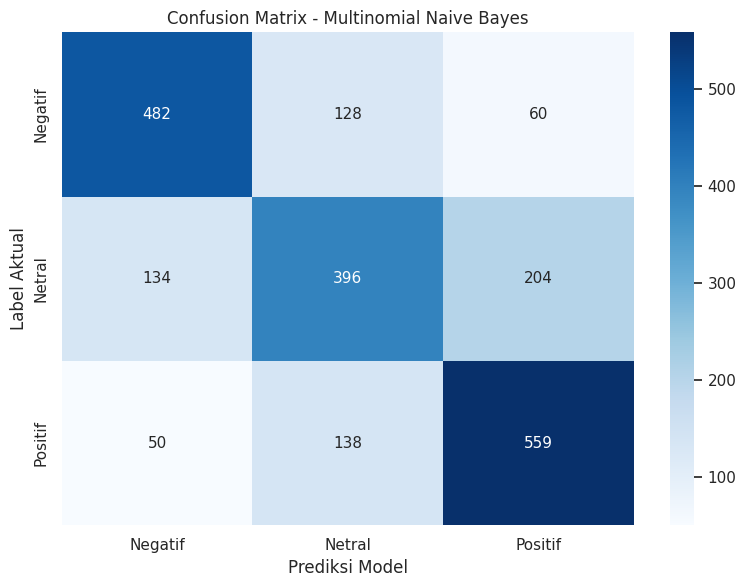

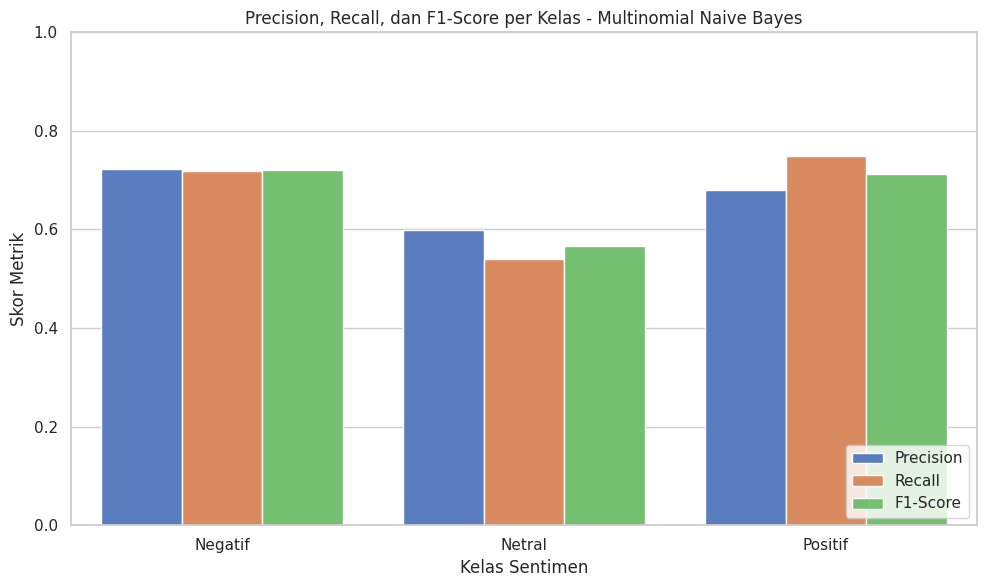

In [86]:
# ==========================================
# BAGIAN 9-11: EVALUASI & VISUALISASI METRIK PADA TEST SET
# ==========================================

# Memeriksa apakah model terbaik sudah dilatih di memory runtime
if 'best_model' not in globals() or best_model is None:
    print("[PERINGATAN] Variabel 'best_model' tidak ditemukan atau belum dilatih!")
    print("Harap pastikan Anda telah menyelesaikan proses pelatihan model pada Bagian 8 terlebih dahulu.")
else:
    y_pred = best_model.predict(X_test_tfidf)

    # 1. Tampilkan Classification Report
    print("\n--- CLASSIFICATION REPORT (TEST SET) ---")
    print(classification_report(y_test, y_pred, target_names=LABEL_NAMES, zero_division=0))

    # 2. Confusion Matrix Heatmap
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=LABEL_NAMES, yticklabels=LABEL_NAMES)
    plt.title("Confusion Matrix - Multinomial Naive Bayes")
    plt.xlabel("Prediksi Model")
    plt.ylabel("Label Aktual")
    plt.tight_layout()
    plt.show()

    # 3. Barplot Precision, Recall, F1-Score per Kelas
    report_dict = classification_report(y_test, y_pred, target_names=LABEL_NAMES, output_dict=True, zero_division=0)

    metrics_data = []
    for kelas in LABEL_NAMES:
        metrics_data.append({
            'Kelas': kelas,
            'Precision': report_dict[kelas]['precision'],
            'Recall': report_dict[kelas]['recall'],
            'F1-Score': report_dict[kelas]['f1-score']
        })

    df_metrics = pd.DataFrame(metrics_data)
    df_melted = pd.melt(df_metrics, id_vars='Kelas', var_name='Metrik', value_name='Skor')

    plt.figure(figsize=(10, 6))
    sns.barplot(x='Kelas', y='Skor', hue='Metrik', data=df_melted, palette='muted')
    plt.ylim(0, 1.0)
    plt.title("Precision, Recall, dan F1-Score per Kelas - Multinomial Naive Bayes")
    plt.ylabel("Skor Metrik")
    plt.xlabel("Kelas Sentimen")
    plt.legend(loc='lower right')
    plt.tight_layout()
    plt.show()

In [87]:
# ==========================================
# BAGIAN 12: PREDIKSI KOMENTAR BARU
# ==========================================

# Memeriksa apakah model dan vectorizer sudah siap di memory runtime
if 'best_model' not in globals() or 'vectorizer' not in globals() or best_model is None:
    print("[PERINGATAN] Model terbaik atau Vectorizer tidak ditemukan di memory runtime!")
    print("Harap selesaikan proses pengekstrakan fitur dan pelatihan model terlebih dahulu.")
else:
    contoh_komentar = [
        "Program makan bergizi gratis ini sangat membantu gizi anak sekolah, mantap!",
        "Masih bingung sistem pembagiannya nanti gimana, semoga merata saja.",
        "Korupsi anggarannya sangat rawan sekali, program ini hanya buang-buang uang."
    ]

    contoh_clean = [clean_text_dataset_2(t) for t in contoh_komentar]
    contoh_tfidf = vectorizer.transform(contoh_clean)

    prediksi_kelas = best_model.predict(contoh_tfidf)
    prediksi_proba = best_model.predict_proba(contoh_tfidf)

    print("\nHasil Prediksi Komentar Baru:")
    for i, teks in enumerate(contoh_komentar):
        prob_neg = prediksi_proba[i][0] * 100
        prob_net = prediksi_proba[i][1] * 100
        prob_pos = prediksi_proba[i][2] * 100
        pred_label = LABEL_NAMES[prediksi_kelas[i]]

        print(f"\nKomentar Asli : '{teks}'")
        print(f"Prediksi      : {pred_label}")
        print(f"Probabilitas  : Negatif({prob_neg:.1f}%), Netral({prob_net:.1f}%), Positif({prob_pos:.1f}%)")


Hasil Prediksi Komentar Baru:

Komentar Asli : 'Program makan bergizi gratis ini sangat membantu gizi anak sekolah, mantap!'
Prediksi      : Positif
Probabilitas  : Negatif(4.4%), Netral(15.5%), Positif(80.1%)

Komentar Asli : 'Masih bingung sistem pembagiannya nanti gimana, semoga merata saja.'
Prediksi      : Negatif
Probabilitas  : Negatif(45.6%), Netral(28.7%), Positif(25.7%)

Komentar Asli : 'Korupsi anggarannya sangat rawan sekali, program ini hanya buang-buang uang.'
Prediksi      : Negatif
Probabilitas  : Negatif(41.5%), Netral(23.1%), Positif(35.4%)


In [88]:
# ==========================================
# BAGIAN 13: PENYIMPANAN MODEL
# ==========================================

# Memeriksa apakah model terbaik sudah dilatih di memory runtime sebelum disimpan
if 'best_model' not in globals() or best_model is None:
    print("[PERINGATAN] Variabel 'best_model' tidak ditemukan! Gagal menyimpan model ke Google Drive.")
else:
    output_dir = os.path.join(dataset_dir, 'model_mnb')
    os.makedirs(output_dir, exist_ok=True)

    path_model = os.path.join(output_dir, 'model_multinomial_nb.pkl')
    path_vectorizer = os.path.join(output_dir, 'tfidf_vectorizer.pkl')
    path_mapping = os.path.join(output_dir, 'label_mapping.pkl')

    # Menyimpan file
    with open(path_model, 'wb') as f:
        pickle.dump(best_model, f)
    with open(path_vectorizer, 'wb') as f:
        pickle.dump(vectorizer, f)
    with open(path_mapping, 'wb') as f:
        pickle.dump(LABEL_NAMES, f)

    print(f"Model dan komponen preprocessing berhasil disimpan ke Google Drive di: {output_dir}")

Model dan komponen preprocessing berhasil disimpan ke Google Drive di: /content/model_mnb


In [89]:
# ==========================================
# BAGIAN 14: KESIMPULAN DAN INTERPRETASI
# ==========================================

# Memeriksa apakah hasil evaluasi dan variabel pendukung sudah siap di memory runtime
if 'y_pred' not in globals() or 'report_dict' not in globals():
    print("[PERINGATAN] Hasil evaluasi model belum tersedia di memory runtime!")
    print("Harap selesaikan proses pelatihan dan evaluasi model terlebih dahulu.")
else:
    test_acc = accuracy_score(y_test, y_pred)
    macro_f1_test = report_dict['macro avg']['f1-score']

    # Identifikasi F1-score tertinggi & terendah
    f1_scores = {kelas: report_dict[kelas]['f1-score'] for kelas in LABEL_NAMES}
    kelas_tertinggi = max(f1_scores, key=f1_scores.get)
    kelas_terendah = min(f1_scores, key=f1_scores.get)

    print("=== KESIMPULAN OTOMATIS EVALUASI MODEL ===")
    print(f"1. Ukuran Subset Data : Training ({len(X_train)}), Validation ({len(X_val)}), Testing ({len(X_test)})")
    print(f"2. Hyperparameter Terbaik: alpha = {best_alpha}")
    print(f"3. Performa Akhir (Test Set) : Akurasi = {test_acc*100:.2f}%, Macro F1-Score = {macro_f1_test:.4f}")
    print(f"4. Analisis Per Kelas:")
    print(f"   - F1-score tertinggi dicapai oleh kelas '{kelas_tertinggi}' dengan skor {f1_scores[kelas_tertinggi]:.4f}")
    print(f"   - F1-score terendah dicapai oleh kelas '{kelas_terendah}' dengan skor {f1_scores[kelas_terendah]:.4f}")
    print("\nCatatan Keterbatasan:")
    print("- Model ini dilatih menggunakan pelabelan leksikon (otomatis), bukan berdasar kebenaran manusia asli (ground truth).")
    print("- Sebagai model baseline linier, Naive Bayes sangat cepat dan handal, namun mengabaikan urutan/konteks kata yang kompleks.")

=== KESIMPULAN OTOMATIS EVALUASI MODEL ===
1. Ukuran Subset Data : Training (17205), Validation (2151), Testing (2151)
2. Hyperparameter Terbaik: alpha = 0.5
3. Performa Akhir (Test Set) : Akurasi = 66.81%, Macro F1-Score = 0.6670
4. Analisis Per Kelas:
   - F1-score tertinggi dicapai oleh kelas 'Negatif' dengan skor 0.7216
   - F1-score terendah dicapai oleh kelas 'Netral' dengan skor 0.5673

Catatan Keterbatasan:
- Model ini dilatih menggunakan pelabelan leksikon (otomatis), bukan berdasar kebenaran manusia asli (ground truth).
- Sebagai model baseline linier, Naive Bayes sangat cepat dan handal, namun mengabaikan urutan/konteks kata yang kompleks.
